# Sumar riesgos: la suma simple, varianza-covarianza y un primer beneficio de diversificación

**Pregunta:** Banco Andino tiene cuatro riesgos que requieren capital: ¿cuánto capital necesita en total, y cuánto de ese
total depende de la forma de sumar los cuatro?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** el notebook 01 del tema 01 (abrir un artefacto versionado); no se necesita otro tema
- **Tiempo de lectura:** unos 35 minutos

## Objetivos

Al terminar este notebook puedes:

- leer las cuatro marginales de Banco Andino (crédito, mercado, riesgo de tasa de interés en la cartera de inversión y
  riesgo operacional) y decir qué son su pérdida esperada, su VaR, su pérdida esperada en la cola y su capital económico;
- sumar los cuatro capitales de las dos maneras más simples, la suma simple (dependencia perfecta) y la regla de la raíz
  cuadrada con una matriz de correlación entre riesgos, y ver al motor rechazar tres matrices inválidas;
- convertir un total en un factor de diversificación y un beneficio, ver cómo el beneficio se agota cuando sube la
  correlación, y leer el beneficio que recibe cada riesgo;
- explicar por qué la suma simple no es una cota superior para un VaR, con el peor caso versionado como evidencia.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del notebook que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el notebook e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importaciones, versiones y lector de los documentos versionados (tres carpetas bajo la raíz del repositorio)
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.aggregation import simple
from riskvalidation.validation import aggregation as agg_tests

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))
DERIVED = Path("../../..").resolve() / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Este notebook lee el caso de capital y estrés de Contraste, **C18**: cuánto capital necesita un banco una vez sumados sus riesgos, y cuánto de la respuesta depende de la forma de sumarlos.

- **Propietario y licencia:** los documentos los escribe el flujo sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este notebook son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este notebook, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (el escenario base: su bloque `outputs.aggregation` tiene las cuatro marginales, la matriz de correlación, la banda de métodos de agregación, la asignación de Euler y la diversificación) y `data/derived/C18/t-copula-baseline.json` (la misma agregación con la referencia de Rosenberg y Schuermann). Toda ruta es relativa a la raíz del repositorio.
- **Lo que el documento no tiene:** el millón de pérdidas simuladas detrás de cada marginal. Tiene cuatro números resumen por marginal, que es todo lo que necesita este notebook; los notebooks 02 y 03 de este tema reconstruyen una simulación a partir de ellos.

La celda siguiente encuentra la raíz del repositorio (el notebook está tres carpetas bajo ella) y define un lector que se detiene con la ruta del archivo cuando falta uno.

In [2]:
# Leer el escenario base: el bloque de agregación tiene las marginales, la matriz y la banda
baseline = read_json("C18/baseline.json")
agg = baseline["outputs"]["aggregation"]
marginals = agg["marginals"]
risks = [m["risk"] for m in marginals]
LABEL = {"credit": "crédito", "market": "mercado", "irrbb": "tasa de interés",
         "operational": "operacional"}
names = [LABEL[r] for r in risks]
band = {(row["method"], row["nu"]): row for row in agg["band"]}

## Método

### Paso 1: el capital de cada riesgo

Contraste mide cada riesgo a **un año y al nivel de 99,9 por ciento** y trabaja con el **capital económico**, la pérdida inesperada: el VaR de la distribución de pérdidas menos su pérdida esperada,

$$EC = \mathrm{VaR}_{0.999}(L) - \mathrm{EL}.$$

La pérdida esperada en la cola (ES) es la pérdida media más allá del VaR. El documento tiene los cuatro números de cada riesgo, en millones de CLP.

La celda siguiente dibuja, para cada riesgo, la pérdida esperada, el capital económico, el VaR y la pérdida esperada en la
cola que tiene el documento, en miles de millones de pesos.

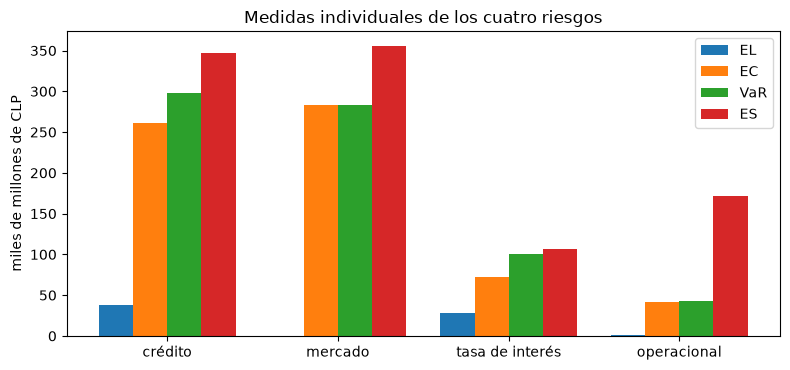

In [3]:
# Las cuatro medidas individuales de cada riesgo, en miles de millones de CLP
ec = np.array([m["ec_clp_m"] for m in marginals])
measures = {"EL": "el_clp_m", "EC": "ec_clp_m", "VaR": "var_clp_m", "ES": "es_clp_m"}
x = np.arange(len(risks))
fig, ax = plt.subplots(figsize=(8, 3.8))
for k, (label, key) in enumerate(measures.items()):
    ax.bar(x + (k - 1.5) * 0.2, [m[key] / 1e3 for m in marginals], width=0.2, label=label)
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylabel("miles de millones de CLP")
ax.set_title("Medidas individuales de los cuatro riesgos")
ax.legend()
fig.tight_layout()
plt.show()

El crédito y el mercado son los dos grandes, cada uno cerca de 260 a 285 mil millones de pesos de capital económico; el
riesgo de tasa de interés es una cuarta parte de eso y el operacional todavía menos. Fíjate en el operacional: su
pérdida esperada en la cola (171 mil millones) es cuatro veces su VaR, que es la firma de una cola pesada, mientras que el
riesgo de mercado no tiene pérdida esperada porque sus pérdidas están centradas en cero. La figura muestra cuatro números
individuales por riesgo y nada sobre cómo se mueven juntos los riesgos, que es de lo que trata el resto del notebook.

### Paso 2: la suma simple

El total más simple suma los cuatro capitales,

$$EC_{\text{tot}} = \sum_k EC_k.$$

Supone que los cuatro malos años llegan siempre juntos (dependencia perfecta), y es el **capital principal** del caso: la autoevaluación interna chilena suma el capital necesario por cada riesgo. Toda otra cifra de este notebook es información que se muestra al lado, nunca un reemplazo.

La celda siguiente suma los cuatro capitales con `simple_sum` del motor e imprime el total junto a la parte de cada riesgo.

In [4]:
# Sumar los cuatro capitales económicos con el motor e imprimir la parte de cada riesgo en la suma
total_simple = simple.simple_sum(ec)
print("suma simple, millones de CLP", round(total_simple, 1))
for risk, value in zip(risks, ec):
    print(f"{LABEL[risk]:16s} {value:10,.0f} {value / total_simple:6.1%}")

suma simple, millones de CLP 658045.9
crédito             260,607  39.6%
mercado             283,435  43.1%
tasa de interés      72,824  11.1%
operacional          41,179   6.3%


### Paso 3: la matriz de correlación entre riesgos

Los malos años no siempre coinciden, así que un banco puede sumar los capitales con una matriz de correlación $R$. La matriz de este caso es una convención tomada de Rosenberg y Schuermann (2006): mercado con crédito 0,5, mercado y crédito con riesgo operacional 0,2, y el documento extiende el 0,5 al riesgo de tasa de interés. Una matriz solo sirve si es simétrica, tiene diagonal unitaria, entradas en $[-1, 1]$ y ningún valor propio negativo (semidefinida positiva). `check_correlation` comprueba las cuatro cosas y lanza `ValueError` si falla alguna.

La celda siguiente valida la matriz versionada con `check_correlation` y luego le ofrece tres matrices inválidas, cada una
de las cuales el motor debe rechazar.

In [5]:
# Validar la matriz versionada y luego mostrar el rechazo de tres matrices inválidas
R = np.array(agg["correlation"]["matrix"])
simple.check_correlation(R)
print("menor valor propio de la matriz versionada", round(float(np.linalg.eigvalsh(R)[0]), 4))
invalid = {
    "no semidefinida positiva": [[1, 0.9, -0.9], [0.9, 1, 0.9], [-0.9, 0.9, 1]],
    "no simétrica": [[1, 0.5], [0.2, 1]],
    "diagonal distinta de 1": [[2, 0.5], [0.5, 1]],
}
for why, matrix in invalid.items():
    try:
        simple.check_correlation(np.array(matrix, dtype=float))
        print(why, ": aceptada")
    except ValueError:
        print(why, ": rechazada")

menor valor propio de la matriz versionada 0.5
no semidefinida positiva : rechazada
no simétrica : rechazada
diagonal distinta de 1 : rechazada


### Paso 4: varianza-covarianza, la regla de la raíz cuadrada

Con una matriz válida el capital total es

$$EC_{\text{tot}} = \sqrt{EC^{\top} R \, EC} = \sqrt{\sum_{j}\sum_{k} R_{jk}\, EC_j\, EC_k}.$$

Es exacta cuando las pérdidas son elípticas con un escalamiento de cuantiles común, y una aproximación en otro caso (dossier 05, G.1). Dos límites muestran qué hace la regla: con $R = I$ (riesgos independientes) es la raíz de la suma de cuadrados, y con $R$ de puros unos (dependencia perfecta) es la suma simple.

La celda siguiente llama a `variance_covariance` y luego a los dos límites: la matriz identidad contra la raíz de la suma
de cuadrados, y la matriz de unos contra la suma simple.

In [6]:
# La regla de la raíz cuadrada con la matriz versionada y con sus dos límites
total_vc = simple.variance_covariance(ec, R)
independent = simple.variance_covariance(ec, np.eye(4))
comonotone = simple.variance_covariance(ec, np.ones((4, 4)))
print("regla de la raíz cuadrada", round(total_vc, 1))
root_squares = float(np.sqrt((ec ** 2).sum()))
print("matriz identidad", round(independent, 1), "raíz de la suma de cuadrados", round(root_squares, 1))
print("matriz de unos", round(comonotone, 1), "suma simple", round(total_simple, 1))

regla de la raíz cuadrada 528106.3
matriz identidad 394018.8 raíz de la suma de cuadrados 394018.8
matriz de unos 658045.9 suma simple 658045.9


### Paso 5: el factor de diversificación y qué lo mueve

El **factor de diversificación** es el total sobre la suma de los capitales por separado,

$$DF = \frac{\rho(L)}{\sum_k \rho(L_k)},$$

y el **beneficio** es $1 - DF$. Un factor menor que 1 significa que los riesgos no salen mal todos juntos. El factor no está obligado a ser a lo más 1: un VaR no es subaditivo, y el motor nunca repara un factor sobre 1 (paso 7).

La celda siguiente calcula el factor del total de la raíz cuadrada con `diversification_factor`, recorre una correlación
común de 0 a 1 y dibuja el beneficio contra ella, con la matriz propia del caso marcada.

factor y beneficio del caso 0.8025 0.1975
beneficio, porcentaje 19.75


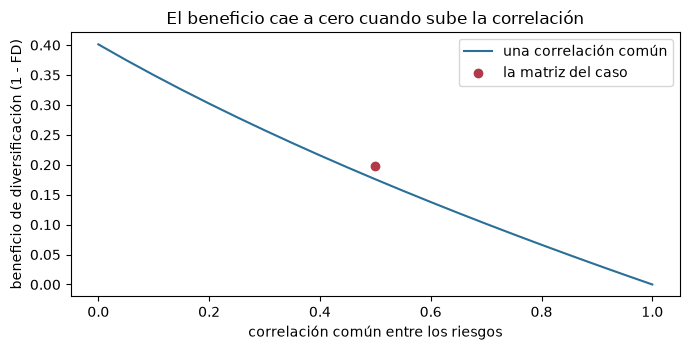

beneficio con correlación común 0, 0.5 y 1 [0.4012, 0.1758, 0.0]


In [7]:
# El factor de diversificación del total de la raíz cuadrada y el beneficio cuando una correlación común va de 0
# a 1
factor = simple.diversification_factor(total_vc, ec)
print("factor y beneficio del caso", round(factor, 4), round(1 - factor, 4))
print("beneficio, porcentaje", round((1 - factor) * 100, 2))
rhos = np.linspace(0, 1, 21)
benefit = []
for rho in rhos:
    common = np.full((4, 4), rho) + (1 - rho) * np.eye(4)
    benefit.append(1 - simple.diversification_factor(simple.variance_covariance(ec, common), ec))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(rhos, benefit, color="#2a6f97", label="una correlación común")
ax.scatter([0.5], [1 - factor], color="#b23a48", zorder=3, label="la matriz del caso")
ax.set_xlabel("correlación común entre los riesgos")
ax.set_ylabel("beneficio de diversificación (1 - FD)")
ax.set_title("El beneficio cae a cero cuando sube la correlación")
ax.legend()
fig.tight_layout()
plt.show()
print("beneficio con correlación común 0, 0.5 y 1", [round(benefit[i], 4) for i in (0, 10, 20)])

La curva es todo el argumento para validar una matriz de correlación antes de usarla. Con riesgos independientes la regla
de la raíz cuadrada da un beneficio de cerca de 40 por ciento, con una correlación común de 0,5 cerca de 18 por ciento y
con dependencia perfecta ninguno. El punto rojo es la matriz propia del caso, que no es una correlación común sino una
convención (0,5 entre mercado, crédito y tasa de interés, 0,2 con el riesgo operacional), y cae en 19,75 por ciento, algo
sobre la curva de 0,5 porque el riesgo operacional está atado solo débilmente al resto. La figura muestra la sensibilidad
de la regla a su entrada; no dice qué correlación es la correcta, y ningún número del documento lo dice.

### Paso 6: quién recibe el beneficio

Un total se puede repartir entre los riesgos con el **principio de Euler** (Tasche, 2007): la contribución del riesgo $k$ es la derivada del total respecto del tamaño de ese riesgo, y las contribuciones suman el total. El documento reparte así la pérdida esperada en la cola del agregado con cópula gaussiana (el notebook 02 muestra cómo). El **beneficio de Euler de un riesgo** es $1 - \rho(L_k \mid L) / \rho(L_k)$: su contribución frente a su medida por separado.

La celda siguiente toma las contribuciones de Euler versionadas de la pérdida esperada en la cola, recalcula el beneficio de
cada riesgo con `euler_diversification_benefit` y dibuja la pérdida esperada individual contra la contribución de cada riesgo.

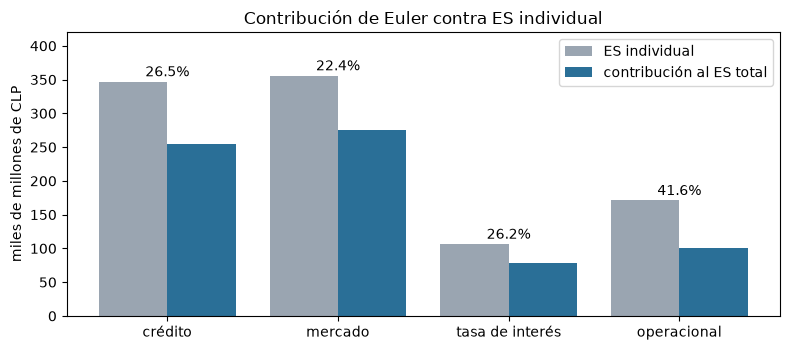

{'crédito': 0.2653, 'mercado': 0.2243, 'tasa de interés': 0.2617, 'operacional': 0.4159}


In [8]:
# El beneficio de Euler de cada riesgo desde su contribución versionada y su ES individual
contribution = {row["risk"]: row["contribution_clp_m"] for row in agg["euler"]["allocation"]}
euler_benefit = [simple.euler_diversification_benefit(contribution[m["risk"]], m["es_clp_m"]) for m in marginals]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(x - 0.2, [m["es_clp_m"] / 1e3 for m in marginals], width=0.4, label="ES individual", color="#9aa5b1")
parts = [contribution[r] / 1e3 for r in risks]
ax.bar(x + 0.2, parts, width=0.4, label="contribución al ES total", color="#2a6f97")
for k, value in enumerate(euler_benefit):
    ax.text(k, 8 + marginals[k]["es_clp_m"] / 1e3, f"{value:.1%}", ha="center")
ax.set_xticks(x)
ax.set_xticklabels(names)
ax.set_ylim(0, 420)
ax.set_ylabel("miles de millones de CLP")
ax.set_title("Contribución de Euler contra ES individual")
ax.legend()
fig.tight_layout()
plt.show()
print(dict(zip(names, [round(b, 4) for b in euler_benefit])))

Cada barra gris es más alta que su vecina azul, porque cada riesgo aporta menos a la cola del total que si estuviera solo:
esa brecha es su beneficio de Euler, escrito sobre las barras. El riesgo operacional recibe el mayor beneficio (41,6 por
ciento) porque su pérdida es grande solo en años en que los otros no lo son, y el de mercado el menor (22,4 por ciento)
porque está más atado al crédito y a la tasa de interés. Estos beneficios se miden sobre la pérdida esperada en la cola del
agregado con cópula gaussiana, así que no se comparan con el 19,75 por ciento del total de la raíz cuadrada: otro total,
otra medida de riesgo, otro número.

### Paso 7: la suma simple no es una cota superior

Es natural leer la suma simple como lo más que pueden necesitar los cuatro riesgos. Para un VaR no lo es: **un VaR no es subaditivo**, así que el VaR de una suma puede superar la suma de los VaR (Embrechts, McNeil y Straumann, 2002; Embrechts, Puccetti y Rueschendorf, 2013). La banda del documento incluye el **peor caso** sobre toda dependencia posible entre estas cuatro marginales, calculado con el algoritmo de reordenamiento (notebook 03).

La celda siguiente convierte el peor caso versionado en un factor y ejecuta dos veces la prueba `diversification_sign` del
motor, sobre las filas diversificadas solas y con el peor caso añadido.

In [9]:
# Convertir el peor caso versionado en un factor y ejecutar la prueba de signo con él y sin él
worst = band[("worst-case", None)]["capital_clp_m"]
worst_factor = simple.diversification_factor(worst, ec)
diversified = [r["diversification_factor"] for r in agg["band"]
               if r["method"] in ("variance-covariance", "gaussian-copula", "t-copula")]
cases = (("solo filas diversificadas", diversified),
         ("con el peor caso", diversified + [worst_factor]))
for label, factors in cases:
    result = agg_tests.diversification_sign(factors)
    print(f"{label:30s} mayor factor {result.statistic:.4f}  filas sobre 1 {result.extras['count_above_one']}")
print("peor caso, millones de CLP", round(worst, 1), "sobre la suma simple", round(worst_factor, 4))

solo filas diversificadas      mayor factor 0.8394  filas sobre 1 0
con el peor caso               mayor factor 1.2512  filas sobre 1 1
peor caso, millones de CLP 823331.5 sobre la suma simple 1.2512


### Paso 8: una referencia publicada, al lado del resultado y nunca como puerta

Rosenberg y Schuermann (2006) encontraron que la aproximación aditiva, que no supone diversificación, suele sobrestimar el riesgo entre un 30 y un 40 por ciento en un banco grande típico. La función `rosenberg_schuermann_reference` del motor calcula la misma razón para este caso, suma simple sobre capital con cópula gaussiana menos 1, e indica si cae en ese rango. La prueba siempre es verde: la fila existe para mostrarse.

La celda siguiente llama a `rosenberg_schuermann_reference` con la suma simple y el capital con cópula gaussiana de la banda.

In [10]:
# El exceso aditivo de este caso, suma simple sobre capital con cópula gaussiana menos uno
gaussian = band[("gaussian-copula", None)]["capital_clp_m"]
reference = agg_tests.rosenberg_schuermann_reference(total_simple, gaussian)
print("exceso aditivo", round(reference.statistic, 4))
print("rango publicado", "30 a 40 por ciento")

exceso aditivo 0.3376
rango publicado 30 a 40 por ciento


## Resultados

La última figura pone la escalera completa lado a lado: cada fila de la banda versionada, con la suma simple como línea
vertical. Las dos barras azules son las que este notebook recalculó en forma cerrada.

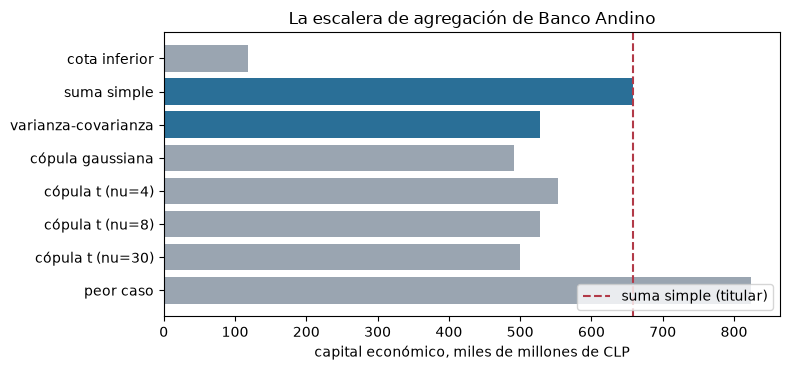

In [11]:
# Dibujar la banda versionada como barras con la suma simple como línea vertical y marcar las filas recalculadas
# aquí
names = {"lower-bound": "cota inferior", "simple-sum": "suma simple",
         "variance-covariance": "varianza-covarianza", "gaussian-copula": "cópula gaussiana",
         "t-copula": "cópula t", "worst-case": "peor caso"}
labels = [names[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in agg["band"]]
recomputed = {names["simple-sum"], names["variance-covariance"]}
colours = ["#2a6f97" if label in recomputed else "#9aa5b1" for label in labels]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(labels[::-1], [r["capital_clp_m"] / 1e3 for r in agg["band"]][::-1], color=colours[::-1])
ax.axvline(total_simple / 1e3, color="#b23a48", linestyle="--", label="suma simple (titular)")
ax.set_xlabel("capital económico, miles de millones de CLP")
ax.set_title("La escalera de agregación de Banco Andino")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

Lee las barras contra la línea discontinua. Todo lo construido sobre una correlación o una cópula queda a su izquierda,
entre 492 y 552 mil millones de pesos, y la cota inferior queda muy a la izquierda porque es el mejor caso en que los
riesgos se compensan. El peor caso queda a la derecha de la línea, que es la sorpresa del paso 7: para un VaR la suma de
los capitales no es el techo. Las barras dicen dónde cae cada método, no cuál es correcto, y la banda de dependencia del
notebook 03 se construye justamente sobre esa dispersión.

**Respuesta:** los cuatro capitales suman 658.046 millones de pesos (la suma simple, el titular del caso); la regla de la
raíz cuadrada con la matriz de correlación del caso da 528.106 millones, un factor de 0,8025 y un beneficio de 19,75 por
ciento, y el beneficio va de 40 por ciento con correlación 0 a nada con correlación 1. El peor caso, 823.332 millones, es
1,2512 veces la suma simple, así que la suma no es una cota superior para un VaR: la prueba de signo es verde sobre las
filas diversificadas (mayor factor 0,8394) y roja una vez incluido el peor caso. El exceso aditivo de este caso es 0,3376,
dentro del 30 a 40 por ciento publicado.

Lo que este notebook no muestra: las filas de cópula de la banda se leyeron y no se recalcularon, porque el documento tiene
números resumen y no las pérdidas simuladas (el notebook 02 construye una simulación); y Banco Andino es sintético, así
que ninguna de estas cifras es una afirmación sobre un banco real.

## Resumen

- El capital económico es el VaR menos la pérdida esperada, por riesgo, a un año y al 99,9 por ciento; el documento tiene los cuatro números de cada uno de los cuatro riesgos.
- La suma simple es el capital principal; la regla de la raíz cuadrada necesita una matriz de correlación válida, que `check_correlation` hace cumplir.
- El factor de diversificación es el total sobre la suma de los capitales; su beneficio se agota cuando la correlación sube a 1.
- Las contribuciones de Euler suman el total y dan a cada riesgo su propio beneficio.
- Un VaR no es subaditivo: el peor caso versionado supera la suma simple, así que la suma no es una cota superior, y la prueba de signo se pone roja cuando se lo incluye.
- El rango de Rosenberg y Schuermann es una referencia para leer al lado del resultado, nunca un umbral.

**Qué probar a continuación.** Cambia una entrada fuera de la diagonal de la matriz del paso 3 y mira moverse el factor del paso 5. Luego sigue con el notebook 02, que reemplaza la regla de la raíz cuadrada por cópulas y muestra de dónde salen las filas gaussiana y t versionadas.

## Referencias

- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Embrechts, P., Puccetti, G. y Rueschendorf, L. (2013), Model uncertainty and VaR aggregation, Journal of Banking and Finance 37(8). https://doi.org/10.1016/j.jbankfin.2013.03.014
- Tasche, D. (2007), Capital allocation to business units and sub-portfolios: the Euler principle (arXiv 0708.2542). https://arxiv.org/abs/0708.2542
- Embrechts, P., McNeil, A. y Straumann, D. (2002), Correlation and dependence in risk management: properties and pitfalls, en Dempster (ed.), Risk Management: Value at Risk and Beyond, Cambridge University Press. https://doi.org/10.1017/CBO9780511615337.008
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (las funciones de agregación del motor) y `docs/design/features/c18/requirements.md` (los requisitos del caso).